# Prevedere il prezzo delle case con una regressione



# 1. EDA (Exploratory data analysis )
- importare il df
- studio il df: guardare i nomi ei tipi delle colonne
- valori mancanti (per colonna)
- duplicati
- distribuzioni dei dati

In [36]:
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

In [37]:
path = ('dataset_case_regressione.csv')
df = pd.read_csv(path)
df.head()

,id_annuncio,superficie_mq,stanze,distanza_centro_km,eta_immobile_anni,zona,ascensore,prezzo_euro
0,ANN-0001,45.0,2,8.0,5.0,Semicentro,Si,247044
1,ANN-0002,124.0,4,11.5,53.0,Semicentro,Si,484877
2,ANN-0003,110.0,3,6.8,25.0,Semicentro,No,367667
3,ANN-0004,85.0,2,9.5,32.0,NaN,Si,396385
4,ANN-0005,85.0,2,13.4,10.0,Periferia,Si,346220


In [38]:
print('struttura df', df.shape)
print('numero righe', df.shape[0])

struttura df (320, 8)
numero righe 320


In [39]:
## controllo le righe duplicate
print('righe dpulicate', df.duplicated().sum())
## controllo dei valori nulli
print('valori nulli', df.isnull().sum())

righe dpulicate 0
valori nulli id_annuncio            0
superficie_mq         22
stanze                 0
distanza_centro_km     0
eta_immobile_anni     30
zona                  13
ascensore             10
prezzo_euro            0
dtype: int64


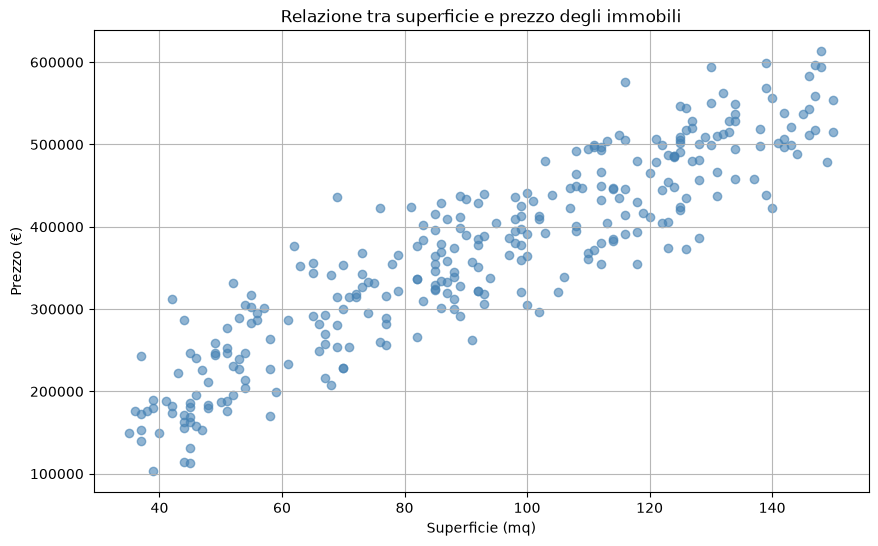

In [40]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['superficie_mq'],
    df['prezzo_euro'],
    alpha=0.6,
    color='steelblue'
)

plt.xlabel('Superficie (mq)')
plt.ylabel('Prezzo (€)')
plt.title('Relazione tra superficie e prezzo degli immobili')
plt.grid(True, alpha=0.9)

plt.show()


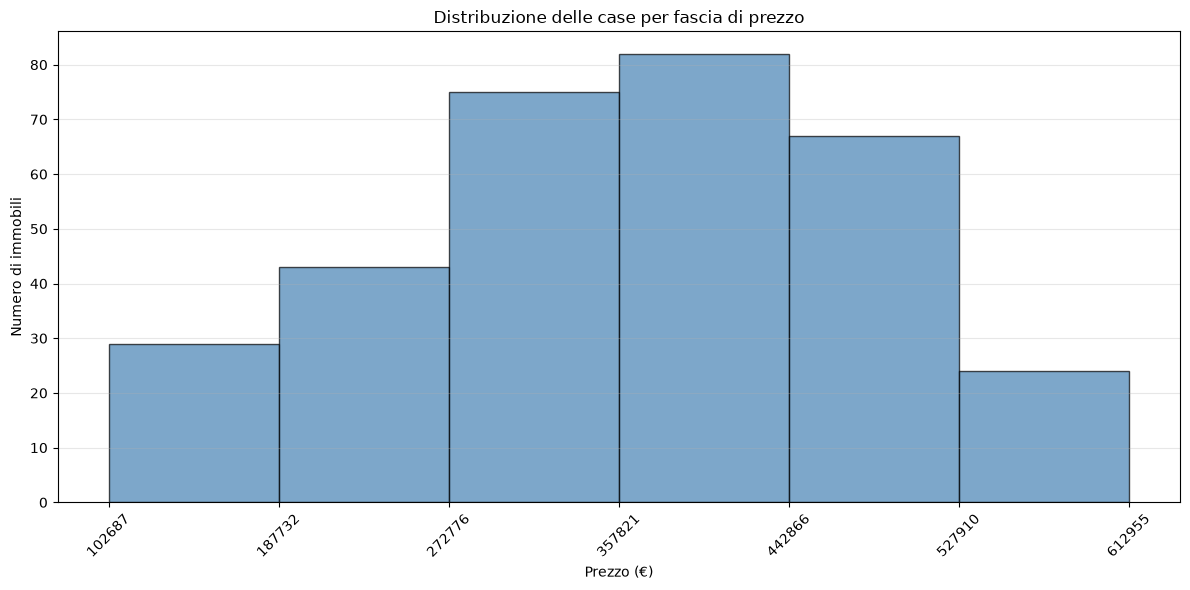

In [41]:

import matplotlib.pyplot as plt
import numpy as np

n_bins = 6  # Numero di bin desiderato

bins = np.linspace(
    df['prezzo_euro'].min(),
    df['prezzo_euro'].max(),
    n_bins + 1
)

plt.figure(figsize=(12, 6))

plt.hist(
    df['prezzo_euro'],
    bins=bins,
    color='steelblue',
    edgecolor='black',
    alpha=0.7
)

plt.xticks(bins, rotation=45)
plt.xlabel('Prezzo (€)')
plt.ylabel('Numero di immobili')
plt.title('Distribuzione delle case per fascia di prezzo')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### Dobbiamo sempre guardarci la correlazione delle varie colonne
noi vogliamo che siano molto correlate con la colonna che vogliamo prevedere e poco correlate tra di loro
questo per escludere le colonne che portano la stessa informazione, anche perchè ( non in questo caso ) ma generalmene vogliamo ridurre il numero di colonne max 15 ( se siete disperati 20 )

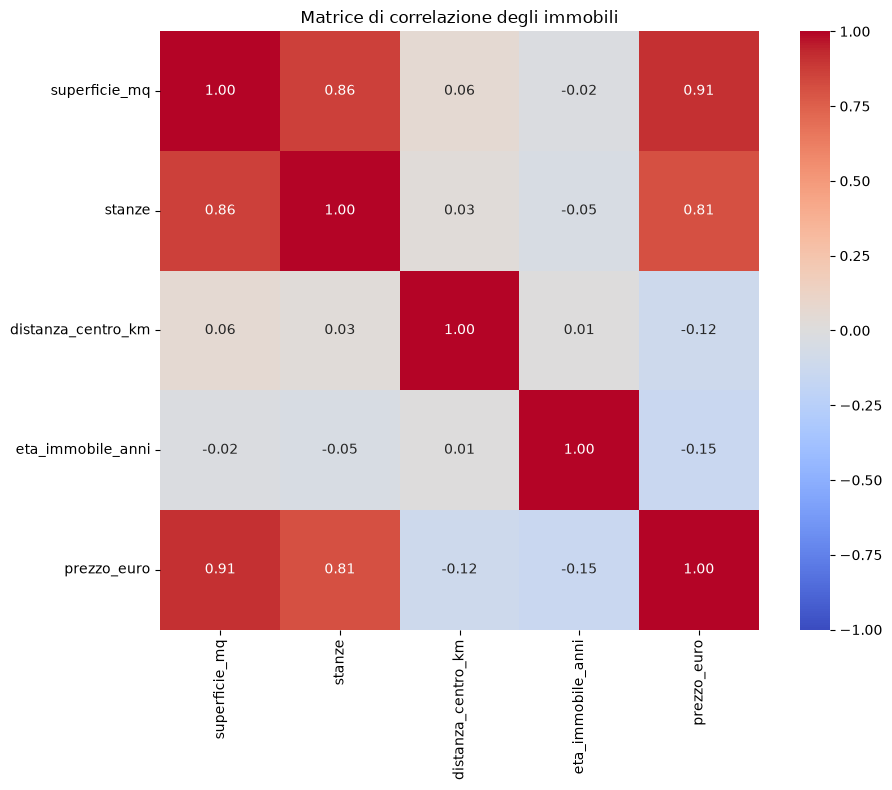

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

# Seleziono le variabili numeriche
colonne = [
    'superficie_mq',
    'stanze',
    'distanza_centro_km',
    'eta_immobile_anni',
    'prezzo_euro'
]

# Calcolo la matrice di correlazione
corr_matrix = df[colonne].corr()

# Visualizzazione
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title('Matrice di correlazione degli immobili')
plt.tight_layout()
plt.show()


In [43]:
df

,id_annuncio,superficie_mq,stanze,distanza_centro_km,eta_immobile_anni,zona,ascensore,prezzo_euro
0,ANN-0001,45.0,2,8.0,5.0,Semicentro,Si,247044
1,ANN-0002,124.0,4,11.5,53.0,Semicentro,Si,484877
2,ANN-0003,110.0,3,6.8,25.0,Semicentro,No,367667
3,ANN-0004,85.0,2,9.5,32.0,NaN,Si,396385
4,ANN-0005,85.0,2,13.4,10.0,Periferia,Si,346220
...,...,...,...,...,...,...,...,...
315,ANN-0316,111.0,3,0.8,55.0,Periferia,No,371904
316,ANN-0317,119.0,4,17.9,0.0,Semicentro,NaN,416553
317,ANN-0318,NaN,4,10.7,19.0,Semicentro,Si,415087
318,ANN-0319,143.0,4,2.7,55.0,Semicentro,No,520907


# 2. Regressione lineare
- divisione tra input e output
- x contiene le colonne che utilizziamo per fae una predizione
- y : (prezzo_euro) è quello che noi dobbiamo prevedere
- NOTA BENE non bisogna MAI mettere y all'interno delle colonne della x!!!!!!!!!! altrimenti abbiamo DATA LEAKAGE

ora il nostro obiettivo è fare una baseline per poterlo confrontare con un modello che pensiamo possa performare bene , se vediamo che il nostro modello performa peggio della baseline abbiamo un problema

In [ ]:
colonne_numeriche = ['superficie_mq', 'stanze', 'distanza_centro_km','eta_immobile_anni']
colonne_categoriche = ['zona', 'ascensore']
colonne_input = colonne_numeriche+ colonne_categoriche

X = df[colonne_input]
y = df['prezzo_euro']
print('dimensione x:', X.shape)
print('dimensione y:', y.shape)


dimensione x: (320, 6)
dimensione y: (320,)


# 3. suddividiamo tra training e test
si utilizza una funzione che sichiama train_test_split generalmente si utilizza il 20 % come test ( test_size = 0.2) e 80 % per il training, un altro parametro che si setta è il random_state = 42 per rendere riproducibile ad altri il vostro esperimento

NB lo split va fatto prima di fare il preprocessing, cioè prima di scalare i dati e prima di riempire i valori nulli onde evitare data leakage

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42 )